## CRC cancer

In [1]:
import pandas as pd
import os

In [2]:
# 加载数据集
file_path = '../ELIFE pancancer ready-to-use data.csv'
data = pd.read_csv(file_path)

In [8]:
positive_samples = data[data['Diagnosis'] == "CRC cancer"]
negative_samples = data[data['Label'] == 0]

num_negative = len(positive_samples) * 1  # 负样本数量是正样本的 1 倍
negative_samples = negative_samples.sample(n=num_negative, random_state=42)  # 随机采样负样本

# 合并正负样本
CRC_sample = pd.concat([positive_samples, negative_samples], ignore_index=True)
CRC_sample = CRC_sample.drop(columns=["SampleID", "Cohort", "Diagnosis"])
CRC_sample.to_csv("CRC_sample.csv", index=False)

In [24]:
CRC_data = pd.read_csv("CRC_sample.csv")
CRC_data

,Label,TMD_1,TMD_2,TMD_3,TMD_4,TMD_5,TMD_6,TMD_7,TMD_8,TMD_9,...,MOTIF_END_TTCG,MOTIF_END_TTCT,MOTIF_END_TTGA,MOTIF_END_TTGC,MOTIF_END_TTGG,MOTIF_END_TTGT,MOTIF_END_TTTA,MOTIF_END_TTTC,MOTIF_END_TTTG,MOTIF_END_TTTT
0,1,0.945946,0.212766,0.048159,0.448864,0.909091,0.962264,0.833333,0.259136,0.210332,...,0.000369,0.004654,0.004149,0.002549,0.003337,0.003637,0.006426,0.005217,0.004955,0.009115
1,1,0.919689,0.132450,0.032520,0.259843,0.962441,0.929825,1.000000,0.135593,0.125683,...,0.000389,0.004502,0.004078,0.002582,0.003425,0.003632,0.006092,0.004851,0.004758,0.008561
2,1,0.972222,0.104167,0.314225,0.568106,0.937107,0.798165,0.923077,0.308571,0.317568,...,0.000372,0.004602,0.004179,0.002534,0.003296,0.003759,0.006432,0.005152,0.004902,0.009133
3,1,0.957143,0.080460,0.017857,0.101639,0.955975,0.962963,0.875000,0.152866,0.137255,...,0.000366,0.004421,0.004086,0.002496,0.003195,0.003542,0.006161,0.004880,0.004826,0.008596
4,1,0.912409,0.087248,0.032967,0.113139,0.797101,0.969231,0.972222,0.184000,0.179916,...,0.000382,0.004507,0.003974,0.002540,0.003296,0.003625,0.006027,0.004905,0.004689,0.008658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.963636,0.059494,0.048622,0.076720,0.954155,1.000000,0.938775,0.258242,0.118971,...,0.000407,0.004450,0.003973,0.002549,0.003232,0.003625,0.006101,0.004890,0.004743,0.008656
314,0,0.960000,0.021277,0.103448,0.136546,0.964286,1.000000,0.978261,0.173410,0.154412,...,0.000394,0.004393,0.003809,0.002495,0.003422,0.003530,0.005293,0.004551,0.004645,0.007831
315,0,0.978261,0.083333,0.000000,0.031250,0.953488,1.000000,0.714286,0.640000,0.074074,...,0.000398,0.004372,0.003740,0.002512,0.003419,0.003563,0.005366,0.004740,0.004575,0.007858
316,0,0.950596,0.043760,0.059347,0.058915,0.969262,0.915842,0.974684,0.328947,0.200000,...,0.000381,0.004600,0.004049,0.002618,0.003273,0.003696,0.005926,0.004861,0.004777,0.008629


### Fscore

In [2]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "CRC_sample_FscoreSorted.csv"
data = pd.read_csv(file_path)

In [3]:
data

,class,MOTIF_END_CAAA,MOTIF_END_CAAG,MOTIF_END_TGCC,MOTIF_END_CGCT,MOTIF_END_CAAC,MOTIF_END_TGCT,MOTIF_END_TGCA,MOTIF_END_GCCT,MOTIF_END_CAAT,...,GWMD_chr10_7,GWMD_chr9_79,CNA_19:15000001-16000000,CNA_1:78000001-79000000,GWMD_chr2_217,flen_112,CNA_8:91000001-92000000,GWMD_chr6_19,CNA_17:47000001-48000000,GWMD_chr6_26
0,1,0.009949,0.006592,0.003104,0.000530,0.003667,0.004344,0.004948,0.003728,0.005559,...,0.786475,0.815372,0.955414,1.001460,0.832258,0.002305,1.02149,0.821573,1.022770,0.831584
1,1,0.009502,0.006611,0.003125,0.000589,0.003445,0.004286,0.005072,0.003823,0.005277,...,0.800301,0.810628,0.949736,0.992489,0.837917,0.001144,1.06493,0.844991,1.046560,0.827623
2,1,0.010231,0.006417,0.003003,0.000550,0.003593,0.004334,0.004904,0.003681,0.005649,...,0.822281,0.827379,0.920299,1.015150,0.840715,0.002123,1.11461,0.818245,1.010520,0.827209
3,1,0.009809,0.006518,0.002948,0.000543,0.003582,0.004127,0.004887,0.003798,0.005513,...,0.805325,0.838334,0.921996,1.025830,0.838667,0.001094,1.02100,0.831981,0.985174,0.827944
4,1,0.008984,0.006297,0.003269,0.000630,0.003529,0.004359,0.004997,0.004172,0.005091,...,0.778544,0.853799,0.921938,1.032610,0.851225,0.001102,1.12624,0.838619,1.062940,0.800641
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.009594,0.006362,0.003106,0.000624,0.003495,0.004239,0.004885,0.003643,0.005426,...,0.799636,0.855980,0.940544,1.005860,0.863444,0.001352,1.00872,0.801323,0.989656,0.854499
314,0,0.008000,0.006294,0.003744,0.000899,0.003112,0.004837,0.005495,0.004871,0.004281,...,0.767550,0.809145,0.925682,0.945696,0.848635,0.001593,1.21142,0.823808,1.113670,0.842411
315,0,0.007920,0.006068,0.003533,0.000816,0.003305,0.004794,0.005441,0.004769,0.004458,...,0.747978,0.852340,0.969696,1.024730,0.820043,0.001101,1.15164,0.863314,1.033890,0.806643
316,0,0.009064,0.006194,0.003404,0.000721,0.003418,0.004636,0.005172,0.004019,0.005089,...,0.779312,0.825416,0.957873,1.016380,0.833539,0.001592,1.13490,0.804979,1.026960,0.841250


In [56]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [57]:
all_features = X_train.columns.tolist()
auc_train_scores_Fscore = []
auc_val_scores_Fscore = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [58]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Fscore.append(auc_train)
    auc_val_scores_Fscore.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >200:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
{4}
{5}
验证集 AUC 开始下降（0.8615 → 0.8508），连续次数：1
{6}
验证集 AUC 开始下降（0.8508 → 0.8500），连续次数：2
{7}
{8}
验证集 AUC 开始下降（0.8515 → 0.8454），连续次数：1
{9}
验证集 AUC 开始下降（0.8454 → 0.8315），连续次数：2
{10}
{11}
{12}
验证集 AUC 开始下降（0.8685 → 0.8600），连续次数：1
{13}
{14}
验证集 AUC 开始下降（0.8692 → 0.8515），连续次数：1
{15}
验证集 AUC 开始下降（0.8515 → 0.8508），连续次数：2
{16}
验证集 AUC 开始下降（0.8508 → 0.8454），连续次数：3
{17}
{18}
{19}
{20}
验证集 AUC 开始下降（0.8623 → 0.8592），连续次数：1
{21}
验证集 AUC 开始下降（0.8592 → 0.8531），连续次数：2
{22}
{23}
验证集 AUC 开始下降（0.8577 → 0.8408），连续次数：1
{24}
验证集 AUC 开始下降（0.8408 → 0.8362），连续次数：2
{25}
过拟合检测：训练集 AUC=0.9283, 验证集 AUC=0.8100，连续次数：1
验证集 AUC 开始下降（0.8362 → 0.8100），连续次数：3
{26}
{27}
{28}
验证集 AUC 开始下降（0.8446 → 0.8254），连续次数：1
{29}
{30}
验证集 AUC 开始下降（0.8415 → 0.8362），连续次数：1
{31}
{32}
{33}
过拟合检测：训练集 AUC=0.9222, 验证集 AUC=0.8169，连续次数：1
验证集 AUC 开始下降（0.8477 → 0.8169），连续次数：1
{34}
{35}
过拟合检测：训练集 AUC=0.9501, 验证集 AUC=0.8446，连续次数：1
验证集 AUC 开始下降（0.8531 → 0.8446），连续次数：1
{36}
过拟合检测：训练集 AUC=0.9330, 验证集 AUC=0.8308，连续次数：2
验证集 AUC 开始下降（0.8446 → 0.

In [9]:
CRC_sample_FscoreSorted = pd.read_csv("CRC_sample_FscoreSorted.csv")
CRC_sample_FscoreSorted_selected149 = CRC_sample_FscoreSorted.iloc[:, :150]
CRC_sample_FscoreSorted_selected149.to_csv("../Fscore/CRC_sample_FscoreSorted_selected149.csv", index=False)

In [10]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Fscore) + 1),
    "Train_AUC": auc_train_scores_Fscore,
    "Validation_AUC": auc_val_scores_Fscore
})

auc_df.to_csv("AUC_scores_Fscore.csv", index=False)

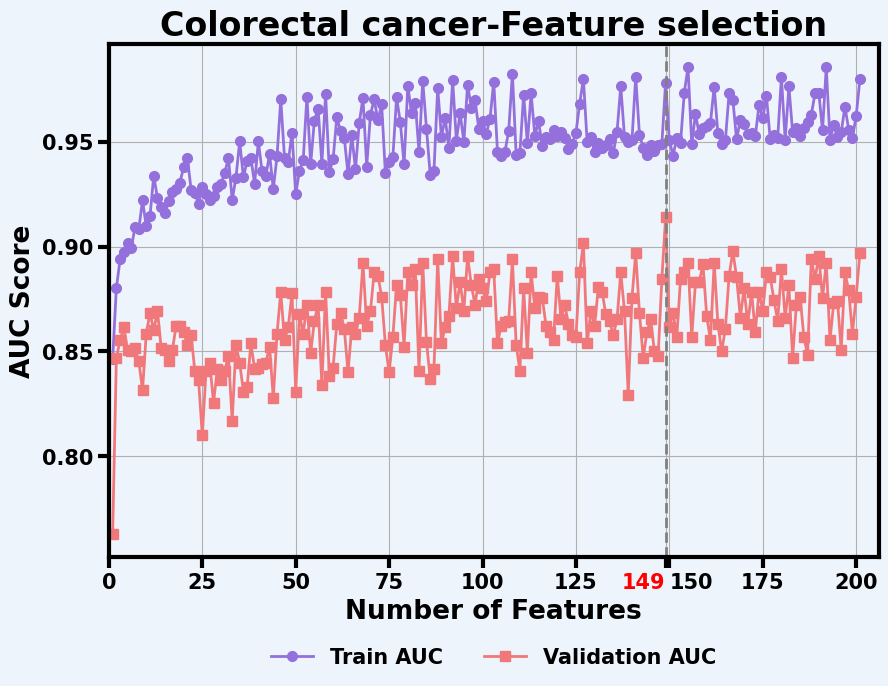

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Fscore.csv")

# 绘制图像
plt.figure(figsize=(9, 7))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o', linewidth=2, markersize=7, color='#9370db')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s', linewidth=2, markersize=7, color="#f1787a")

plt.xlabel("Number of Features", fontsize=19, fontweight='bold')
plt.ylabel("AUC Score", fontsize=19, fontweight='bold')
plt.title("Colorectal cancer-Feature selection", fontsize=24, fontweight='bold')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, prop={'family': 'sans-serif', 'size': 15, 'weight': 'bold'})
plt.grid(True)

# 添加竖线标注特征数 = 149
plt.axvline(x=149, color='gray', linestyle='--', linewidth=2)

# 设置 x 轴刻度并强制包含 149
xticks = sorted(set(plt.xticks()[0].tolist() + [149]))
plt.xticks(xticks)

# 调整标签位置
ax = plt.gca()
for label in ax.get_xticklabels():
    text = label.get_text()
    if text == '149':
        # 向左微调0.3个单位，设置右对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('right')
        label.set_color('red')
        label.set_bbox({'facecolor': 'white', 'alpha': 0, 'edgecolor': 'none'})
    elif text == '150':
        # 向右微调0.3个单位，设置左对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('left')
        label.set_bbox({'facecolor': 'white', 'alpha': 0, 'edgecolor': 'none'})

# 保持网格线在原始位置
ax.xaxis.set_ticks_position('bottom')  # 确保刻度线位置不变

# 调整坐标轴范围防止溢出
ax.set_xlim(left=0, right=max(auc_df["Num_Features"]) + 5)

ax = plt.gca()  # 获取当前坐标轴
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

# 保存图像为 PNG 文件
plt.tight_layout()
plt.savefig("AUC_vs_FeatureCount_Fscore.png", dpi=300)
plt.show()

### ANOVA

In [5]:
import pandas as pd

# 1. 读取最终的 CSV 文件
csv_file = "CRC_sample_AnovaSorted.csv"
df = pd.read_csv(csv_file)

# 2. 读取 ANOVA 排序的特征文件，获取正确的特征名顺序
anova_sorted_file = "../ANOVA/CRC_feature_importance.csv" 
with open(anova_sorted_file, "r") as f:
    sorted_feature_names = [line.split()[1] for line in f.readlines()]  # 取出特征名称

# 3. 获取当前 CSV 文件的列名（去掉第一列 class）
original_column_names = list(df.columns[1:])  # 去掉第 1 列类别标签

# 4. 创建新的列名列表（保持类别标签不变）
new_column_names = ["class"] + sorted_feature_names[:len(original_column_names)]

# 5. 重新设置 DataFrame 的列名
df.columns = new_column_names

# 6. 保存修改后的 CSV 文件
df.to_csv("CRC_sample_AnovaSorted_corrected.csv", index=False)


In [59]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "CRC_sample_AnovaSorted_corrected.csv"
data = pd.read_csv(file_path)

In [60]:
data

,class,MOTIF_END_CAAA,MOTIF_END_CAAG,MOTIF_END_TGCC,MOTIF_END_CGCT,MOTIF_END_CAAC,MOTIF_END_TGCT,MOTIF_END_TGCA,MOTIF_END_GCCT,MOTIF_END_CAAT,...,GWMD_chr10_7,GWMD_chr9_79,CNA_19:15000001-16000000,CNA_1:78000001-79000000,GWMD_chr2_217,flen_112,CNA_8:91000001-92000000,GWMD_chr6_19,CNA_17:47000001-48000000,GWMD_chr6_26
0,1,0.009949,0.006592,0.003104,0.000530,0.003667,0.004344,0.004948,0.003728,0.005559,...,0.786475,0.815372,0.955414,1.001460,0.832258,0.002305,1.02149,0.821573,1.022770,0.831584
1,1,0.009502,0.006611,0.003125,0.000589,0.003445,0.004286,0.005072,0.003823,0.005277,...,0.800301,0.810628,0.949736,0.992489,0.837917,0.001144,1.06493,0.844991,1.046560,0.827623
2,1,0.010231,0.006417,0.003003,0.000550,0.003593,0.004334,0.004904,0.003681,0.005649,...,0.822281,0.827379,0.920299,1.015150,0.840715,0.002123,1.11461,0.818245,1.010520,0.827209
3,1,0.009809,0.006518,0.002948,0.000543,0.003582,0.004127,0.004887,0.003798,0.005513,...,0.805325,0.838334,0.921996,1.025830,0.838667,0.001094,1.02100,0.831981,0.985174,0.827944
4,1,0.008984,0.006297,0.003269,0.000630,0.003529,0.004359,0.004997,0.004172,0.005091,...,0.778544,0.853799,0.921938,1.032610,0.851225,0.001102,1.12624,0.838619,1.062940,0.800641
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.009594,0.006362,0.003106,0.000624,0.003495,0.004239,0.004885,0.003643,0.005426,...,0.799636,0.855980,0.940544,1.005860,0.863444,0.001352,1.00872,0.801323,0.989656,0.854499
314,0,0.008000,0.006294,0.003744,0.000899,0.003112,0.004837,0.005495,0.004871,0.004281,...,0.767550,0.809145,0.925682,0.945696,0.848635,0.001593,1.21142,0.823808,1.113670,0.842411
315,0,0.007920,0.006068,0.003533,0.000816,0.003305,0.004794,0.005441,0.004769,0.004458,...,0.747978,0.852340,0.969696,1.024730,0.820043,0.001101,1.15164,0.863314,1.033890,0.806643
316,0,0.009064,0.006194,0.003404,0.000721,0.003418,0.004636,0.005172,0.004019,0.005089,...,0.779312,0.825416,0.957873,1.016380,0.833539,0.001592,1.13490,0.804979,1.026960,0.841250


In [61]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [62]:
all_features = X_train.columns.tolist()
auc_train_scores_ANOVA = []
auc_val_scores_ANOVA = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1  
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [63]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ANOVA.append(auc_train)
    auc_val_scores_ANOVA.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >200:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
{4}
{5}
验证集 AUC 开始下降（0.8615 → 0.8508），连续次数：1
{6}
验证集 AUC 开始下降（0.8508 → 0.8500），连续次数：2
{7}
{8}
验证集 AUC 开始下降（0.8515 → 0.8454），连续次数：1
{9}
验证集 AUC 开始下降（0.8454 → 0.8315），连续次数：2
{10}
{11}
{12}
验证集 AUC 开始下降（0.8685 → 0.8600），连续次数：1
{13}
{14}
验证集 AUC 开始下降（0.8692 → 0.8515），连续次数：1
{15}
验证集 AUC 开始下降（0.8515 → 0.8508），连续次数：2
{16}
验证集 AUC 开始下降（0.8508 → 0.8454），连续次数：3
{17}
{18}
{19}
{20}
验证集 AUC 开始下降（0.8623 → 0.8592），连续次数：1
{21}
验证集 AUC 开始下降（0.8592 → 0.8531），连续次数：2
{22}
{23}
验证集 AUC 开始下降（0.8577 → 0.8408），连续次数：1
{24}
验证集 AUC 开始下降（0.8408 → 0.8362），连续次数：2
{25}
过拟合检测：训练集 AUC=0.9283, 验证集 AUC=0.8100，连续次数：1
验证集 AUC 开始下降（0.8362 → 0.8100），连续次数：3
{26}
{27}
{28}
验证集 AUC 开始下降（0.8446 → 0.8254），连续次数：1
{29}
{30}
验证集 AUC 开始下降（0.8415 → 0.8362），连续次数：1
{31}
{32}
{33}
过拟合检测：训练集 AUC=0.9222, 验证集 AUC=0.8169，连续次数：1
验证集 AUC 开始下降（0.8477 → 0.8169），连续次数：1
{34}
{35}
过拟合检测：训练集 AUC=0.9501, 验证集 AUC=0.8446，连续次数：1
验证集 AUC 开始下降（0.8531 → 0.8446），连续次数：1
{36}
过拟合检测：训练集 AUC=0.9330, 验证集 AUC=0.8308，连续次数：2
验证集 AUC 开始下降（0.8446 → 0.

In [17]:
CRC_sample_AnovaSorted_corrected = pd.read_csv("CRC_sample_AnovaSorted_corrected.csv")
CRC_sample_AnovaSorted_selected149 = CRC_sample_AnovaSorted_corrected.iloc[:, :150]
CRC_sample_AnovaSorted_selected149.to_csv("../ANOVA/CRC_sample_AnovaSorted_selected149.csv", index=False)

In [64]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ANOVA) + 1),
    "Train_AUC": auc_train_scores_ANOVA,
    "Validation_AUC": auc_val_scores_ANOVA
})

auc_df.to_csv("AUC_scores_ANOVA.csv", index=False)

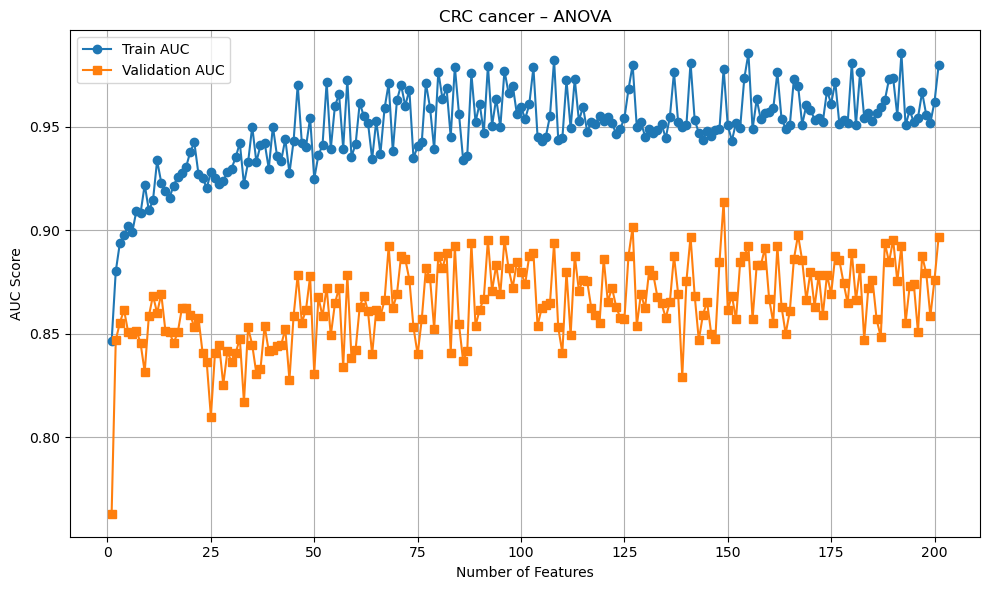

In [65]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ANOVA.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("CRC cancer – ANOVA")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ANOVA.png", dpi=300)
plt.show()

### ReliefF

In [25]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "CRC_sample_ReliefFSorted.csv"
data = pd.read_csv(file_path)

In [26]:
data


,class,MOTIF_END_TGCC,MOTIF_END_TGCA,MOTIF_END_TGCT,MOTIF_END_TCCG,MOTIF_END_TGGT,MOTIF_END_CGCC,MOTIF_END_CGCT,MOTIF_END_GCCT,MOTIF_END_TCTG,...,CNA_5:148000001-149000000,CNA_14:20000001-21000000,TMD_78,TMD_266,CNA_2:148000001-149000000,CNA_2:38000001-39000000,CNA_10:95000001-96000000,TMD_110,CNA_12:119000001-120000000,CNA_3:76000001-77000000
0,1,0.003104,0.004948,0.004344,0.000510,0.003587,0.000514,0.000530,0.003728,0.005700,...,1.016840,0.955719,0.000000,0.111732,0.486646,1.000720,0.529393,0.250000,1.019830,0.961299
1,1,0.003125,0.005072,0.004286,0.000556,0.003724,0.000602,0.000589,0.003823,0.005755,...,0.983344,0.896332,0.030172,0.126582,0.484671,0.990466,0.512577,0.333333,1.019720,0.967737
2,1,0.003003,0.004904,0.004334,0.000517,0.003691,0.000522,0.000550,0.003681,0.005623,...,0.999571,1.104310,0.086207,0.053333,0.488335,1.016100,0.531021,0.866667,0.992915,0.925333
3,1,0.002948,0.004887,0.004127,0.000507,0.003588,0.000539,0.000543,0.003798,0.005634,...,0.975315,1.001610,0.200000,0.007576,0.483908,0.983965,0.508765,0.428571,1.019190,0.956880
4,1,0.003269,0.004997,0.004359,0.000577,0.003730,0.000693,0.000630,0.004172,0.005896,...,1.001250,0.902279,0.000000,0.090909,0.457927,1.011640,0.536970,0.642857,1.011920,0.991108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.003106,0.004885,0.004239,0.000553,0.003743,0.000676,0.000624,0.003643,0.005413,...,1.000560,1.058010,0.006135,0.000000,0.497804,0.989999,0.509929,0.444444,1.015380,0.943079
314,0,0.003744,0.005495,0.004837,0.000739,0.004031,0.000947,0.000899,0.004871,0.006270,...,0.978868,0.810864,0.020619,0.083333,0.439748,0.959618,0.576042,0.714286,1.031330,0.898052
315,0,0.003533,0.005441,0.004794,0.000670,0.004197,0.000957,0.000816,0.004769,0.005874,...,1.030270,0.972322,0.000000,0.000000,0.420342,0.953260,0.490192,0.000000,0.926491,0.903694
316,0,0.003404,0.005172,0.004636,0.000548,0.003927,0.000729,0.000721,0.004019,0.005333,...,1.006210,0.940306,0.007463,0.088803,0.482572,1.012960,0.545655,0.250000,1.039890,0.971132


In [27]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [29]:
all_features = X_train.columns.tolist()
auc_train_scores_ReliefF = []
auc_val_scores_ReliefF = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [30]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ReliefF.append(auc_train)
    auc_val_scores_ReliefF.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >200:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
验证集 AUC 开始下降（0.7723 → 0.7692），连续次数：1
{4}
{5}
验证集 AUC 开始下降（0.7938 → 0.7931），连续次数：1
{6}
验证集 AUC 开始下降（0.7931 → 0.7831），连续次数：2
{7}
验证集 AUC 开始下降（0.7831 → 0.7785），连续次数：3
{8}
{9}
{10}
验证集 AUC 开始下降（0.8654 → 0.8454），连续次数：1
{11}
{12}
{13}
{14}
验证集 AUC 开始下降（0.8854 → 0.8792），连续次数：1
{15}
{16}
验证集 AUC 开始下降（0.8885 → 0.8777），连续次数：1
{17}
{18}
验证集 AUC 开始下降（0.8862 → 0.8815），连续次数：1
{19}
{20}
验证集 AUC 开始下降（0.8938 → 0.8846），连续次数：1
{21}
验证集 AUC 开始下降（0.8846 → 0.8800），连续次数：2
{22}
验证集 AUC 开始下降（0.8800 → 0.8708），连续次数：3
{23}
{24}
验证集 AUC 开始下降（0.8800 → 0.8623），连续次数：1
{25}
{26}
验证集 AUC 开始下降（0.8738 → 0.8623），连续次数：1
{27}
{28}
{29}
验证集 AUC 开始下降（0.8808 → 0.8538），连续次数：1
{30}
{31}
{32}
{33}
验证集 AUC 开始下降（0.8954 → 0.8631），连续次数：1
{34}
{35}
验证集 AUC 开始下降（0.9200 → 0.8915），连续次数：1
{36}
{37}
验证集 AUC 开始下降（0.8969 → 0.8731），连续次数：1
{38}
{39}
验证集 AUC 开始下降（0.9046 → 0.9031），连续次数：1
{40}
{41}
验证集 AUC 开始下降（0.9108 → 0.9046），连续次数：1
{42}
验证集 AUC 开始下降（0.9046 → 0.8877），连续次数：2
{43}
{44}
验证集 AUC 开始下降（0.9138 → 0.9000），连续次数：1
{45}
{46}
验证

In [31]:
CRC_sample_ReliefFSorted = pd.read_csv("CRC_sample_ReliefFSorted.csv")
CRC_sample_ReliefFSorted_selected34 = CRC_sample_ReliefFSorted.iloc[:, :35]
CRC_sample_ReliefFSorted_selected34.to_csv("../ReliefF/CRC_sample_ReliefFSorted_selected34.csv", index=False)

In [32]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ReliefF) + 1),
    "Train_AUC": auc_train_scores_ReliefF,
    "Validation_AUC": auc_val_scores_ReliefF
})

auc_df.to_csv("AUC_scores_ReliefF.csv", index=False)

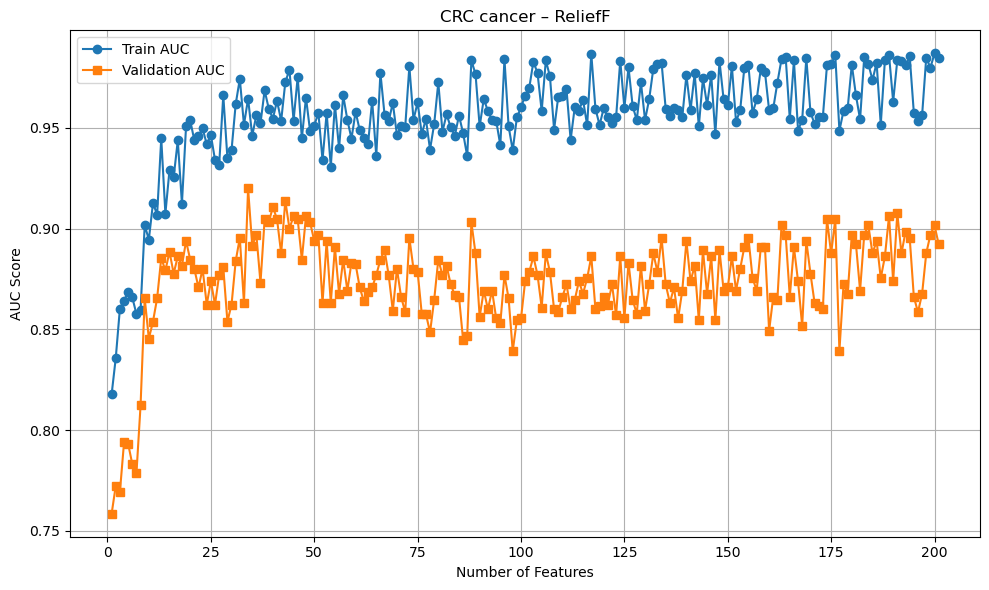

In [50]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("CRC cancer – ReliefF")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ReliefF.png", dpi=300)
plt.show()

### Binomial

In [35]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "CRC_sample_BinomialSorted.csv"
data = pd.read_csv(file_path)

In [36]:
data

,class,TMD_98,TMD_122,TMD_392,TMD_64,TMD_101,TMD_112,TMD_339,TMD_73,TMD_269,...,GWFP_short_14:50000001-55000000,GWFP_short_14:55000001-60000000,GWFP_short_16:80000001-85000000,GWFP_total_14:55000001-60000000,GWFP_total_16:10000001-15000000,GWMD_chr21_10,CNA_9:117000001-118000000,CNA_12:58000001-59000000,GWFP_short_2:105000001-110000000,GWFP_total_11:5000001-10000000
0,1,0.245902,0.055556,0.032787,0.080808,0.022222,0.486486,0.182186,0.000000,0.237705,...,0.312536,0.282356,1.071060,0.283736,0.881954,0.585511,0.995396,0.938015,0.470909,0.593443
1,1,0.000000,0.013333,0.000000,0.050403,0.052381,0.000000,0.062057,0.078431,0.235294,...,0.358518,0.312100,1.076210,0.371371,0.833221,0.389330,0.992910,0.927132,0.471587,0.609340
2,1,0.034483,0.473684,0.294118,0.097973,0.034730,0.228070,0.019108,0.254902,0.437500,...,0.457713,0.363594,0.647547,0.443222,0.641608,0.551689,1.016560,0.970052,0.249534,0.380433
3,1,0.027027,0.000000,0.011765,0.024943,0.005874,0.049587,0.010135,0.100000,0.000000,...,0.477018,0.388961,0.794558,0.418357,0.668444,0.599080,0.990554,0.964851,0.656691,0.458876
4,1,0.000000,0.000000,0.000000,0.002439,0.053114,0.000000,0.000000,0.030000,0.000000,...,0.351547,0.326167,0.866410,0.251687,0.810601,0.527667,1.040790,0.934995,0.331606,0.594811
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.000000,0.000000,0.000000,0.026217,0.008904,0.005464,0.013084,0.002146,0.047619,...,0.147852,0.387586,0.980612,0.287663,0.724181,0.310393,0.961548,0.928595,0.245638,0.559224
314,0,0.000000,0.018868,0.000000,0.021097,0.004107,0.000000,0.004184,0.000000,0.000000,...,-0.009304,-0.081453,0.919624,-0.119113,0.789892,0.354643,0.943031,0.935817,0.263835,0.478393
315,0,0.000000,0.000000,0.000000,0.055556,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.203423,-0.018568,0.721402,-0.015326,0.657052,0.554628,0.938355,0.880318,0.425414,0.598230
316,0,0.000000,0.003012,0.009195,0.005994,0.015041,0.000000,0.010769,0.004587,0.013761,...,0.395445,0.281579,0.899112,0.221596,0.890961,0.517448,0.952962,0.941823,0.155139,0.536606


In [37]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [43]:
all_features = X_train.columns.tolist()
auc_train_scores_Binomial = []
auc_val_scores_Binomial = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.25
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 30
max_decline_tolerance = 5

In [44]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Binomial.append(auc_train)
    auc_val_scores_Binomial.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >150:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}


{3}
{4}
验证集 AUC 开始下降（0.6500 → 0.6162），连续次数：1
{5}
{6}
验证集 AUC 开始下降（0.6538 → 0.6523），连续次数：1
{7}
验证集 AUC 开始下降（0.6523 → 0.6362），连续次数：2
{8}
{9}
{10}
验证集 AUC 开始下降（0.6992 → 0.6546），连续次数：1
{11}
{12}
{13}
验证集 AUC 开始下降（0.7223 → 0.6638），连续次数：1
{14}
{15}
验证集 AUC 开始下降（0.6862 → 0.6631），连续次数：1
{16}
{17}
{18}
验证集 AUC 开始下降（0.7692 → 0.7615），连续次数：1
{19}
验证集 AUC 开始下降（0.7615 → 0.7538），连续次数：2
{20}
验证集 AUC 开始下降（0.7538 → 0.6862），连续次数：3
{21}
验证集 AUC 开始下降（0.6862 → 0.6662），连续次数：4
{22}
{23}
{24}
{25}
验证集 AUC 开始下降（0.7523 → 0.7015），连续次数：1
{26}
{27}
{28}
验证集 AUC 开始下降（0.7292 → 0.7246），连续次数：1
{29}
{30}
验证集 AUC 开始下降（0.7262 → 0.7215），连续次数：1
{31}
{32}
验证集 AUC 开始下降（0.7269 → 0.7215），连续次数：1
{33}
{34}
验证集 AUC 开始下降（0.7415 → 0.7154），连续次数：1
{35}
{36}
验证集 AUC 开始下降（0.7492 → 0.7308），连续次数：1
{37}
{38}
验证集 AUC 开始下降（0.7662 → 0.7138），连续次数：1
{39}
{40}
验证集 AUC 开始下降（0.7246 → 0.6831），连续次数：1
{41}
{42}
验证集 AUC 开始下降（0.7200 → 0.6969），连续次数：1
{43}
{44}
验证集 AUC 开始下降（0.7062 → 0.6692），连续次数：1
{45}
{46}
验证集 AUC 开始下降（0.7554 → 0.7246），连续次数：1
{47}
{48}


In [53]:
CRC_sample_BinomialSorted = pd.read_csv("CRC_sample_BinomialSorted.csv")
CRC_sample_BinomialSorted_selected133 = CRC_sample_BinomialSorted.iloc[:, :134]
CRC_sample_BinomialSorted_selected133.to_csv("../Binomial/CRC_sample_BinomialSorted_selected133.csv", index=False)

In [45]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Binomial) + 1),
    "Train_AUC": auc_train_scores_Binomial,
    "Validation_AUC": auc_val_scores_Binomial
})

auc_df.to_csv("AUC_scores_Binomial.csv", index=False)


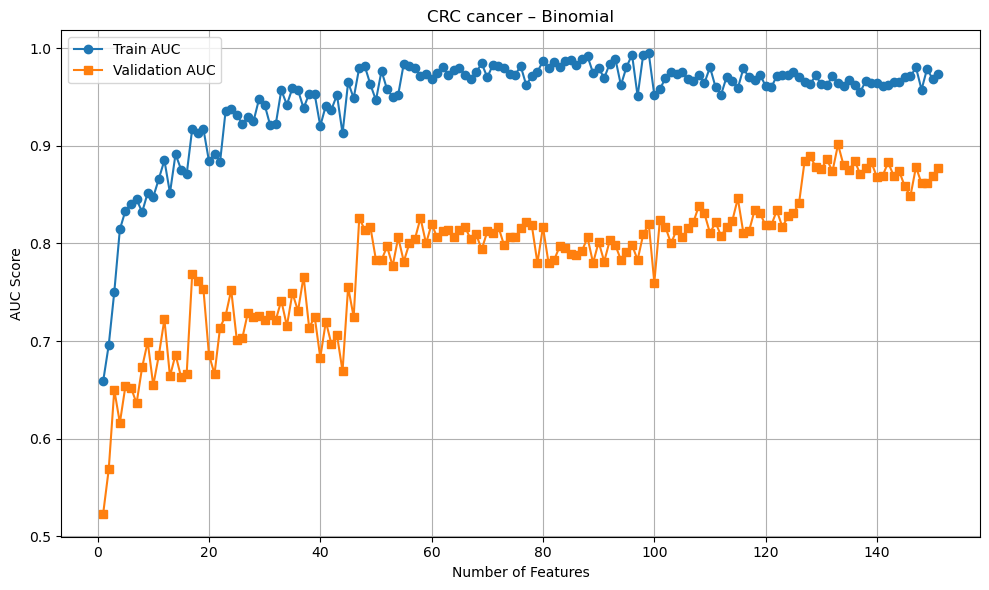

In [49]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Binomial.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("CRC cancer – Binomial")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Binomial.png", dpi=300)
plt.show()

### biomaker分析

In [1]:
import pandas as pd

file_paths = [
    "../ANOVA/CRC_sample_AnovaSorted_selected149.csv",
    "../Binomial/CRC_sample_BinomialSorted_selected133.csv",
    "../Fscore/CRC_sample_FscoreSorted_selected149.csv",
    "../ReliefF/CRC_sample_ReliefFSorted_selected34.csv"
]
dfs = [pd.read_csv(file_path) for file_path in file_paths]
dfs_info = [df.head() for df in dfs]


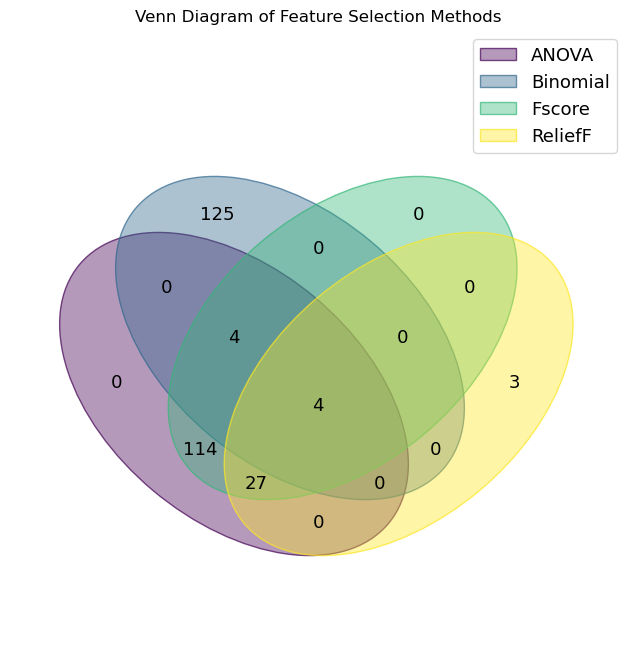

In [2]:
import matplotlib.pyplot as plt
from venn import venn
import pandas as pd

# 加载所有文件
df_anova = dfs[0]
df_binomial = dfs[1]
df_fscore = dfs[2]
df_reliefF = dfs[3]

# 提取每个文件的特征列
anova_features = set(df_anova.columns[1:])
binomial_features = set(df_binomial.columns[1:])
fscore_features = set(df_fscore.columns[1:])
relieff_features = set(df_reliefF.columns[1:])

feature_sets = {
    'ANOVA': anova_features,
    'Binomial': binomial_features,
    'Fscore': fscore_features,
    'ReliefF': relieff_features
}

venn(feature_sets)
plt.title("Venn Diagram of Feature Selection Methods")
plt.show()